# Homework 5: Building a Review Classifier

**Student:** Ishfaq Shah  
**Course:** Web Analytics  
**Professor:** Apostolos Filippas

This notebook summarizes the reproducible data preparation, model evaluation, performance-improvement experiments, exploratory analysis, and LLM comparison. The complete commented implementation is in `rt_scraper.py`, `collect_reviews.py`, `prepare_data.py`, `train_and_analyze.py`, and `llm_compare.py`.

## 1. Data collection and preparation

The Homework 4 Selenium parser is in `rt_scraper.py`. `collect_reviews.py` applies it to a movie list, saves a checkpoint after every movie, and resumes interrupted runs. It records review text, rating, movie identifier, critic, publisher, and date. The committed dataset is a cached snapshot so the analysis can be reproduced without repeating hundreds of live requests; `prepare_data.py` validates and combines fresh parser output or rebuilds the snapshot from the documented public archive.

In [1]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path('.')
summary = json.loads((ROOT / 'results' / 'summary.json').read_text())
pd.Series(summary)

reviews                                                        50000
movies                                                          1000
fresh_reviews                                                  30755
rotten_reviews                                                 19245
fresh_rate                                                    0.6151
median_review_words                                             21.0
train_reviews                                                  40000
test_reviews                                                   10000
train_movies                                                     800
test_movies                                                      200
best_model             Unigram + bigram TF-IDF + logistic regression
best_accuracy                                                 0.7836
best_f1                                                     0.820206
early_fresh_rate                                             0.61404
late_fresh_rate                   

The dataset contains **50,000 reviews from 1,000 movies**, exceeding the required 10,000 reviews and 500 movies. It contains 30,755 Fresh reviews and 19,245 Rotten reviews. The median review is 21 words long.

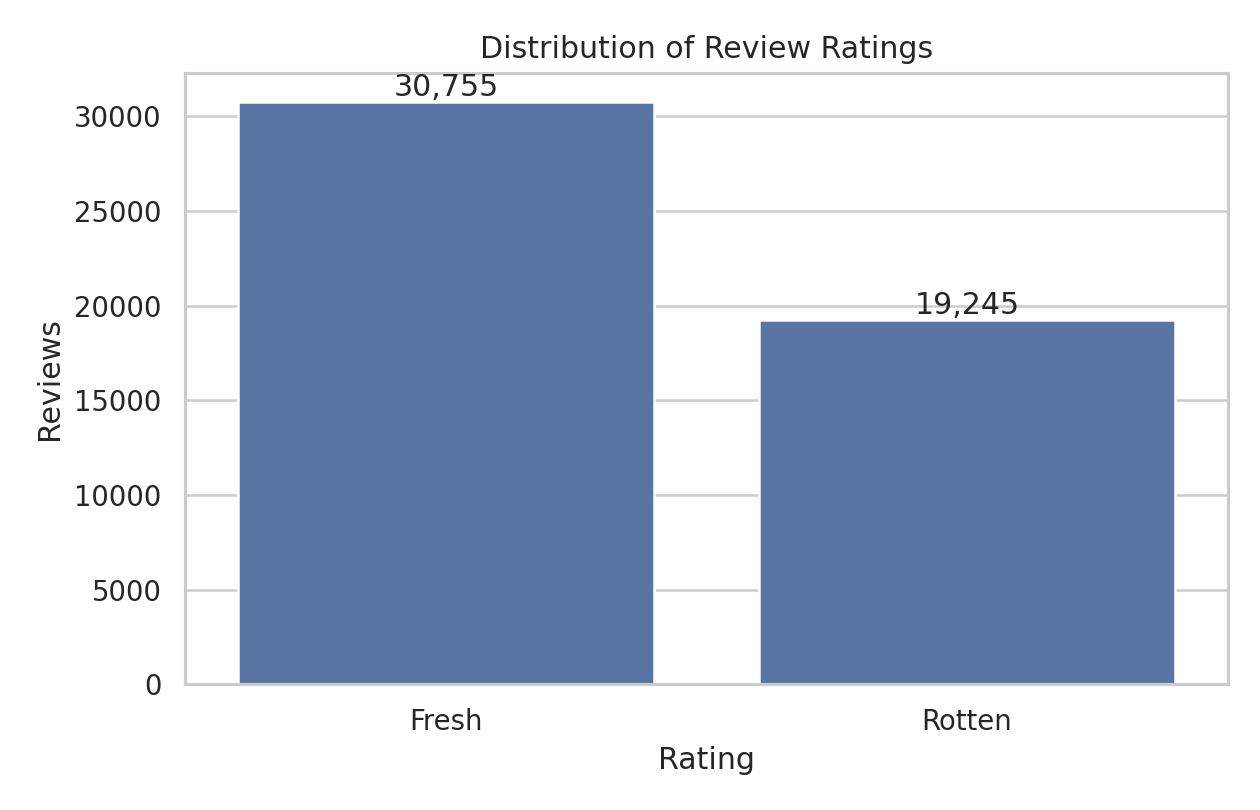

In [2]:
from IPython.display import Image, display
display(Image(filename='results/figures/rating_distribution.png'))

## 2. Train/test design and classifier evaluation

The split was performed by **movie**, not by individual review. Reviews from the 200 test movies never appear in the training set. This produces a more realistic estimate of performance on unseen films. The training set contains 40,000 reviews from 800 movies; the test set contains 10,000 reviews from 200 movies.

In [3]:
models = pd.read_csv('results/model_comparison.csv')
models.round(4)

                                         model  accuracy  precision  recall     f1  roc_auc
 Unigram + bigram TF-IDF + logistic regression    0.7836     0.8356  0.8054 0.8202   0.8644
          Unigram + bigram TF-IDF + linear SVM    0.7830     0.8292  0.8135 0.8213   0.8583
Baseline: unigram TF-IDF + logistic regression    0.7715     0.7788  0.8760 0.8245   0.8490
      Unigram TF-IDF + multinomial Naive Bayes    0.7526     0.7445  0.9080 0.8181   0.8403


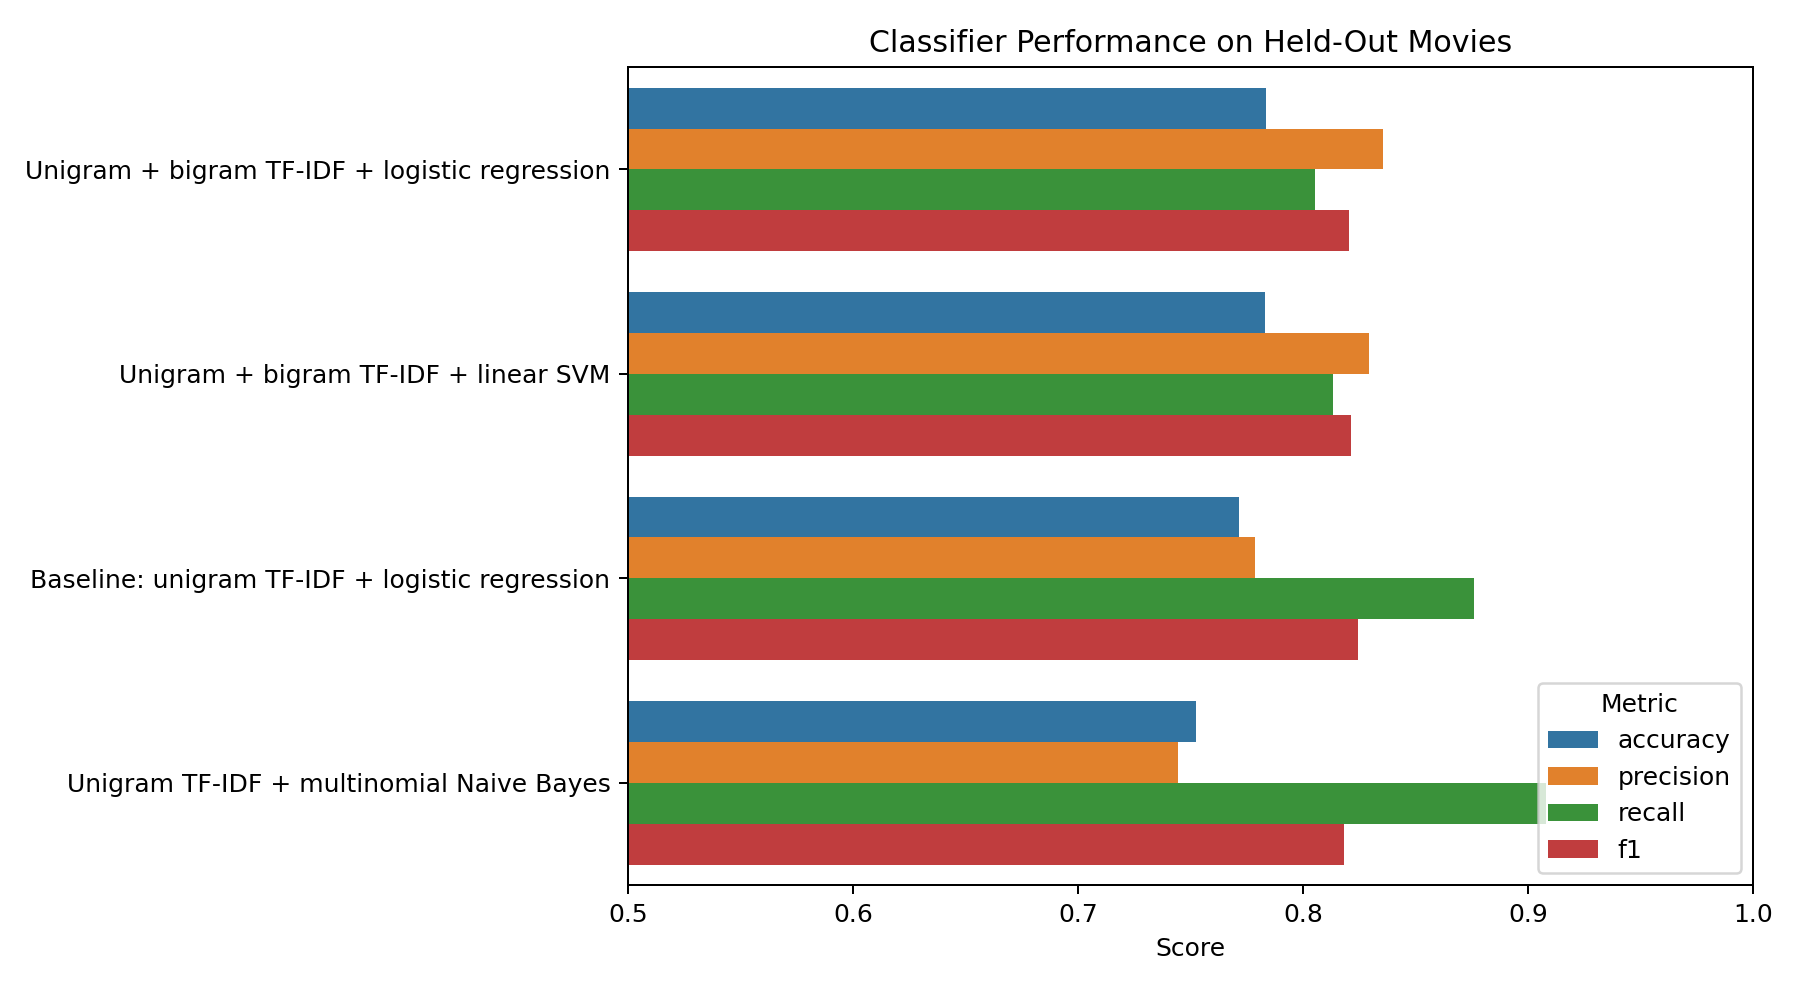

In [4]:
display(Image(filename='results/figures/model_comparison.png'))

The unigram logistic-regression baseline achieved **77.15% accuracy**. Adding bigrams, class weighting, and a tuned regularization value increased accuracy to **78.36%** and ROC-AUC to **0.8644**. Linear SVM was nearly tied at 78.30%. Multinomial Naive Bayes was the weakest model at 75.26%. The changes improved accuracy by 1.21 percentage points, although the baseline retained a slightly higher F1 score because it predicted the majority Fresh class more aggressively.

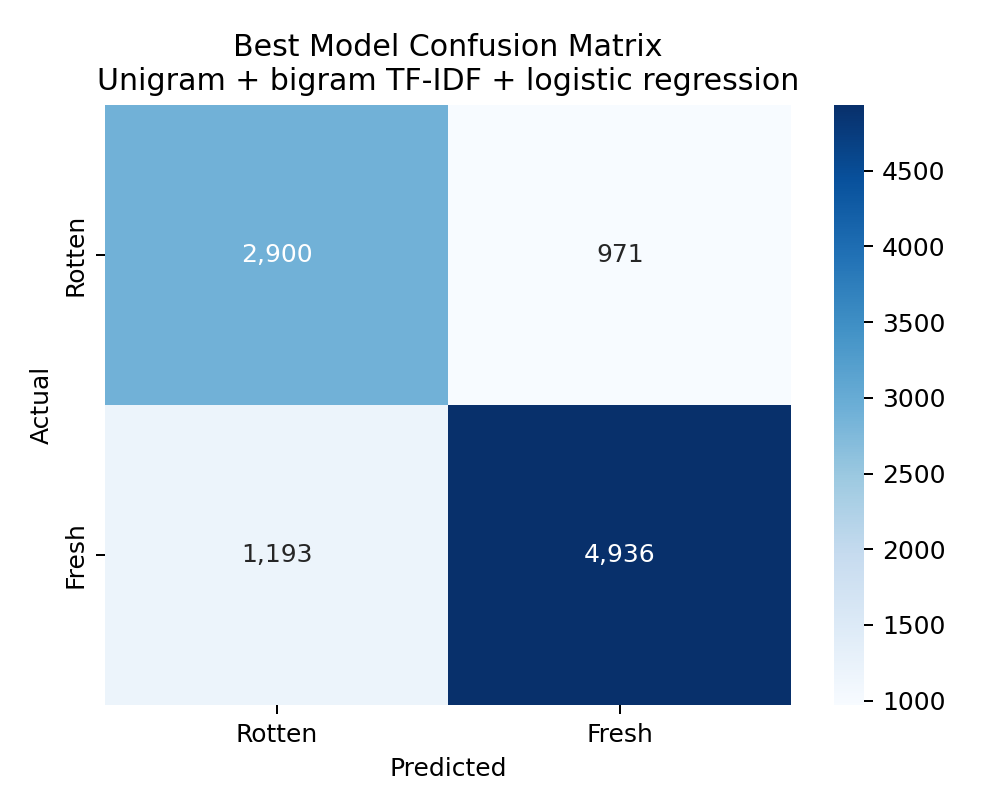

In [5]:
display(Image(filename='results/figures/confusion_matrix.png'))

## 3. Exploratory data analysis

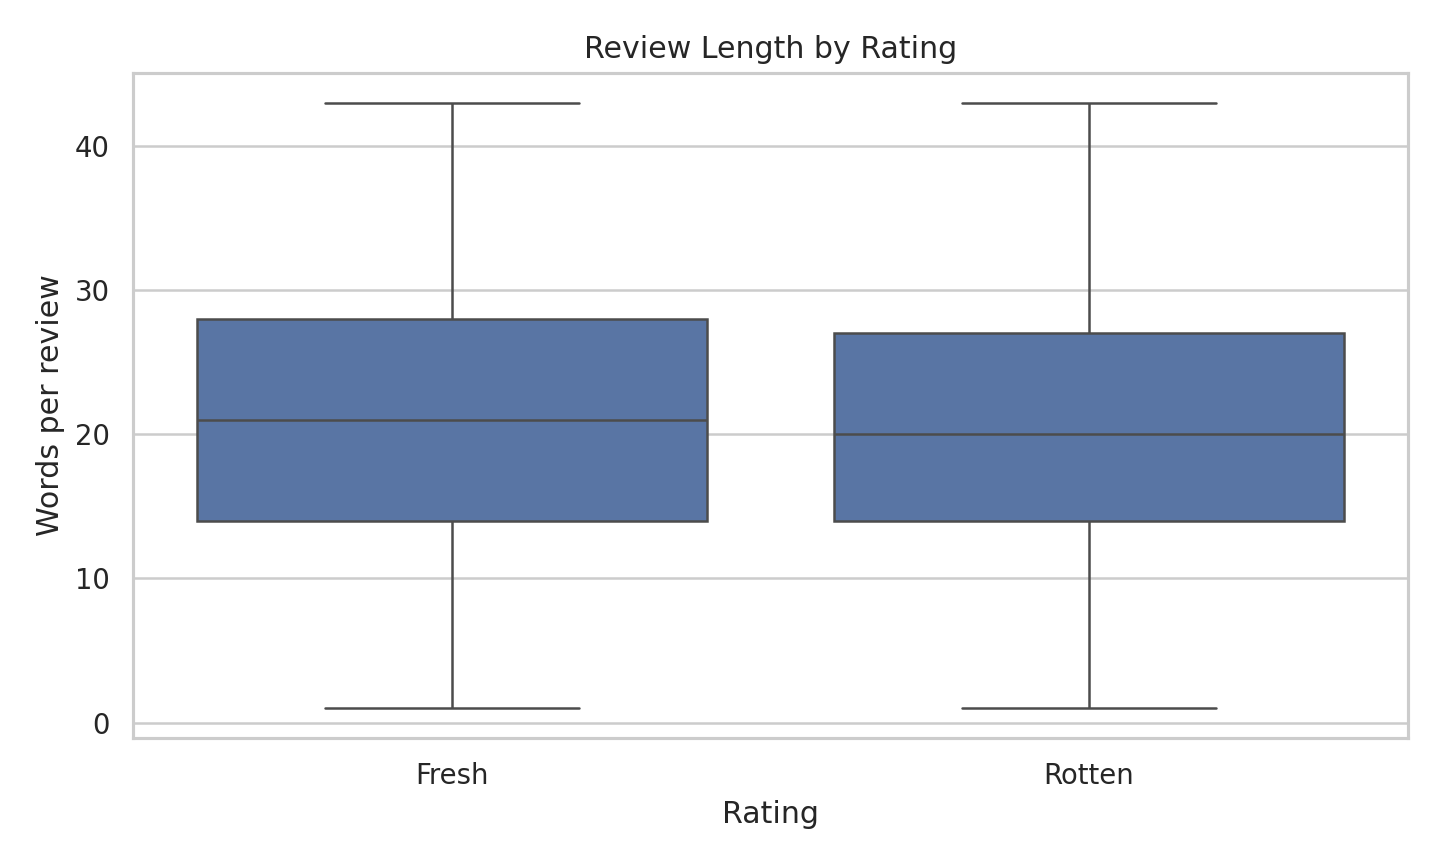

In [6]:
display(Image(filename='results/figures/review_length.png'))

Fresh and Rotten review excerpts have broadly similar lengths, so review length alone is unlikely to explain the classifier's performance. The language within the excerpts provides substantially more predictive information.

In [7]:
early_late = pd.read_csv('results/early_late_rates.csv')
early_late

review_period    mean  count
 Earlier half 0.61404  25000
   Later half 0.61616  25000


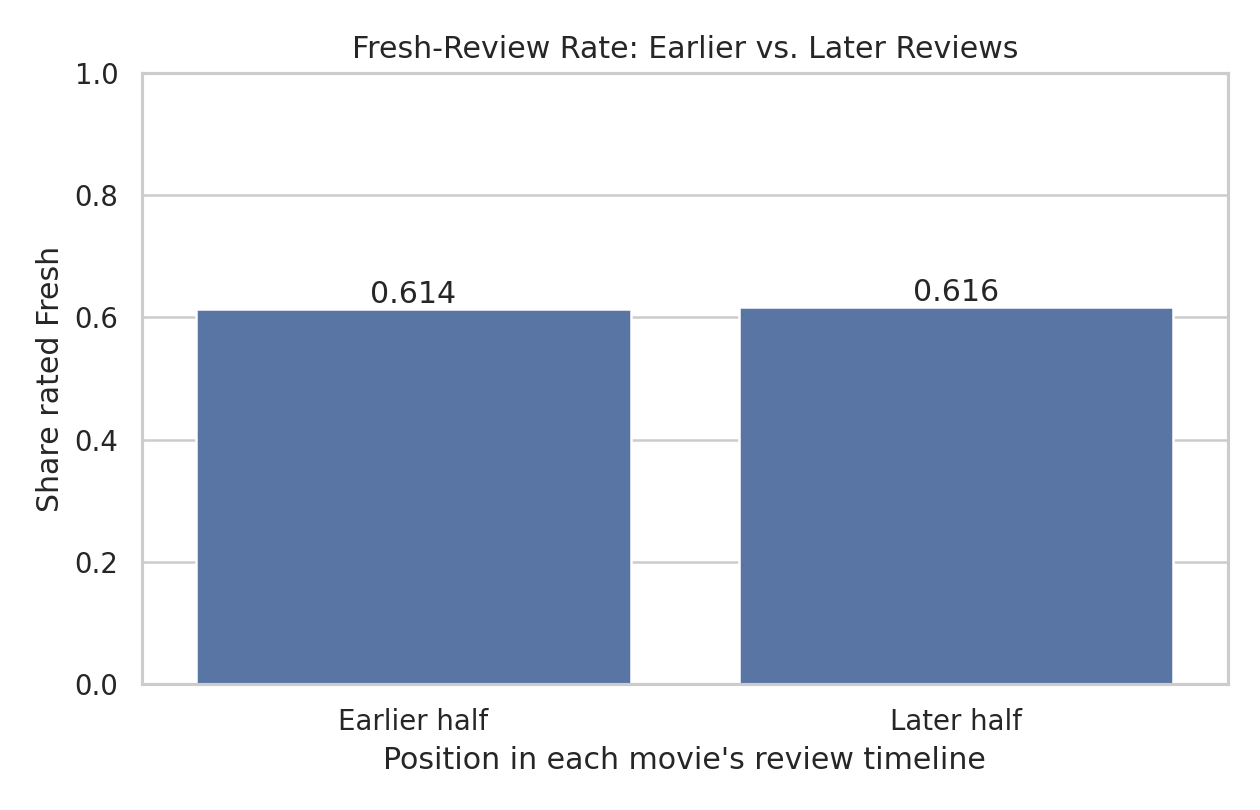

In [8]:
display(Image(filename='results/figures/early_vs_late.png'))

Earlier reviews were 61.40% Fresh and later reviews were 61.62% Fresh. The 0.22 percentage-point difference is negligible in this sample, so there is no evidence that ratings systematically worsen after a movie's earliest reviews.

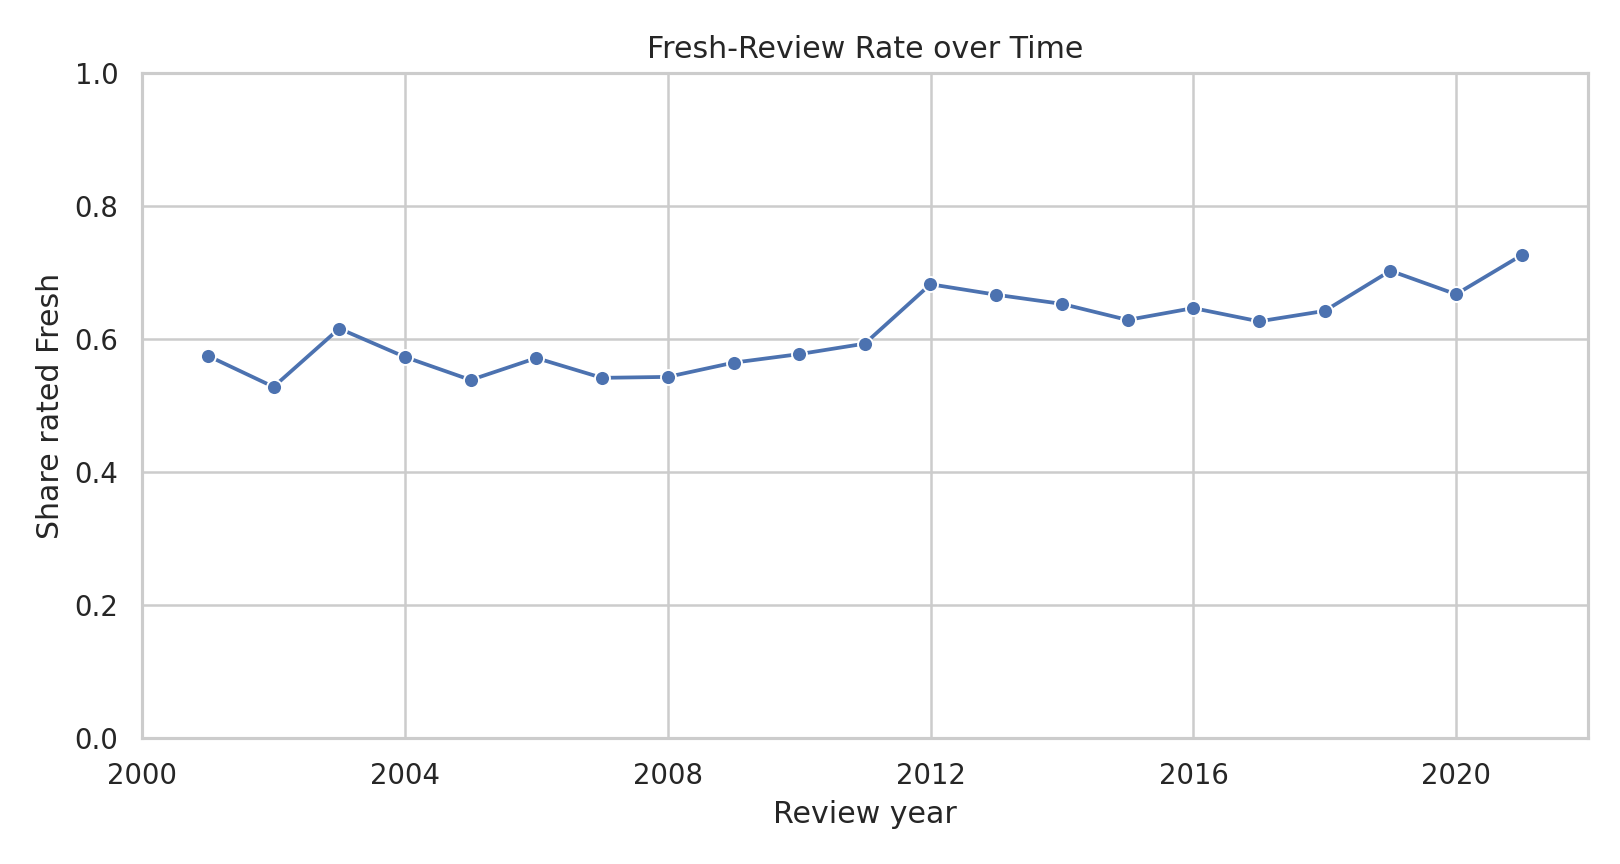

In [9]:
display(Image(filename='results/figures/rating_over_time.png'))

## 4. OpenAI model comparison

`llm_compare.py` draws a fixed random sample of 200 held-out reviews, sends each to `gpt-6-luna`, records token usage, calculates accuracy/precision/recall/F1, and computes the exact average cost using the official November 17, 2026 standard prices of $0.10 per million input tokens and $0.50 per million output tokens.

In [10]:
llm = json.loads((ROOT / 'results' / 'llm_summary.json').read_text())
pd.Series(llm)

model                                                                 gpt-6-luna
reviews_classified                                                           200
accuracy                                                                   0.925
precision                                                               0.944954
recall                                                                  0.919643
f1                                                                      0.932127
total_input_tokens                                                         11033
total_output_tokens                                                         1091
total_cost_usd                                                          0.001649
average_cost_per_review_usd                                             0.000008
input_price_per_million                                                      0.1
output_price_per_million                                                     0.5
traditional_model           

On the exact same 200 held-out reviews, the traditional model achieved **76.50% accuracy** and **0.7930 F1**, while the LLM achieved **92.50% accuracy** and **0.9321 F1**. The LLM cost **$0.00000824 per review**. Its 16-point accuracy advantage is worthwhile for this small batch, although the local model remains preferable for offline, private, or very large repeated workloads.

## 5. Reproducibility

Run `python prepare_data.py`, followed by `python train_and_analyze.py`. After configuring an OpenAI API key, run `python llm_compare.py` and then rerun `python build_deliverables.py` to insert the verified LLM results into this notebook and the PDF report.